# Лабораторная работа №1 — Регрессия: Wine Quality

**Цель:** пройти полный цикл регрессии: EDA → корректное разбиение → константный baseline → линейная регрессия / RBF + Ridge / случайный лес / градиентный бустинг → сравнение RMSE и MAE → интерпретация → ошибки.

**Условие преподавателя:** RMSE на скрытой тестовой выборке должен быть строго меньше **0.70**.

**Данные:** оригинальные `winequality-red.csv` и `winequality-white.csv` (UCI Wine Quality, Cortez et al.). Объединяем красные и белые вина и явно добавляем признак `is_red`; ТЗ не ограничивает тип вина. Оба CSV сохранены в `regression/data/`.

**Принцип честного эксперимента:** тест отделяется до исследования зависимостей; модель и её параметры выбираются исключительно по кросс-валидации на train. Тест открывается один раз в заключительной части. Преобразования обучаются только на тренировочных фолдах с помощью Pipeline.

Источник: https://archive.ics.uci.edu/dataset/186/wine+quality

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.kernel_approximation import Nystroem
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)


Matplotlib is building the font cache; this may take a moment.


## 1. Загрузка и знакомство с данными

В работе используется датасет **Wine Quality** из UCI, содержащий физико-химические характеристики красных и белых вин.

Сначала загружаем два CSV-файла, добавляем признак `is_red` (1 — красное вино, 0 — белое) и объединяем данные в одну таблицу.

**Целевая переменная** — `quality`, числовая оценка качества вина. Остальные столбцы используются как признаки для предсказания.

После загрузки посмотрим размер датасета, первые пять строк и основные статистические характеристики признаков.

In [2]:
def find_data_dir():
    candidates = [Path("data"), Path("regression/data"), Path("../data")]
    for folder in candidates:
        if (folder / "winequality-red.csv").exists() and (folder / "winequality-white.csv").exists():
            return folder
    raise FileNotFoundError("Не найдены CSV: запустите ноутбук из корня репозитория или папки regression.")

data_dir = find_data_dir()
red = pd.read_csv(data_dir / "winequality-red.csv", sep=";")
white = pd.read_csv(data_dir / "winequality-white.csv", sep=";")
red["is_red"] = 1
white["is_red"] = 0
data = pd.concat([red, white], ignore_index=True)
assert data.shape[0] == 6497 and "quality" in data
print("Красное:", len(red), "| Белое:", len(white), "| Всего:", len(data))
display(data.head())
display(data.describe().T)


Красное: 1599 | Белое: 4898 | Всего: 6497


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


## 2. Защищённое разбиение train/test

Выбираем **80% train / 20% test**, воспроизводимый `random_state=42`. Стратификация по `quality` нужна, чтобы редкие оценки были представлены в обеих частях. Тест **не участвует** в EDA, выборе признаков, гиперпараметров и победителя. Многократная проверка гипотез по одному тесту приводит к косвенному переобучению на него. Повторяющиеся наблюдения могут искусственно улучшать оценку — ниже изучим их число (без изменения заранее зафиксированного протокола).

In [3]:
X = data.drop(columns="quality")
y = data["quality"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)
assert set(X_train.index).isdisjoint(set(X_test.index))
print("Дубликатов признаков во всём датасете:", X.duplicated().sum())
print("Дубликатов train-признаков:", X_train.duplicated().sum())
print("Важно: наличие одинаковых признаков в разных строках может завышать качество случайного разбиения.")


Train: (5197, 12) Test: (1300, 12)
Дубликатов признаков во всём датасете: 1177
Дубликатов train-признаков: 791
Важно: наличие одинаковых признаков в разных строках может завышать качество случайного разбиения.


## 3. EDA — только на обучающей выборке

Смотрим на баланс целевых оценок и тип вина, пропуски, корреляции. Корреляции описывают связь, **не причинность**; почти нулевая корреляция не означает, что признак бесполезен для нелинейной модели.

Пропуски (train):


fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
is_red                  0
dtype: int64

Распределение quality (train):


,count
quality,
3,24
4,173
5,1710
6,2269
7,863
8,154
9,4


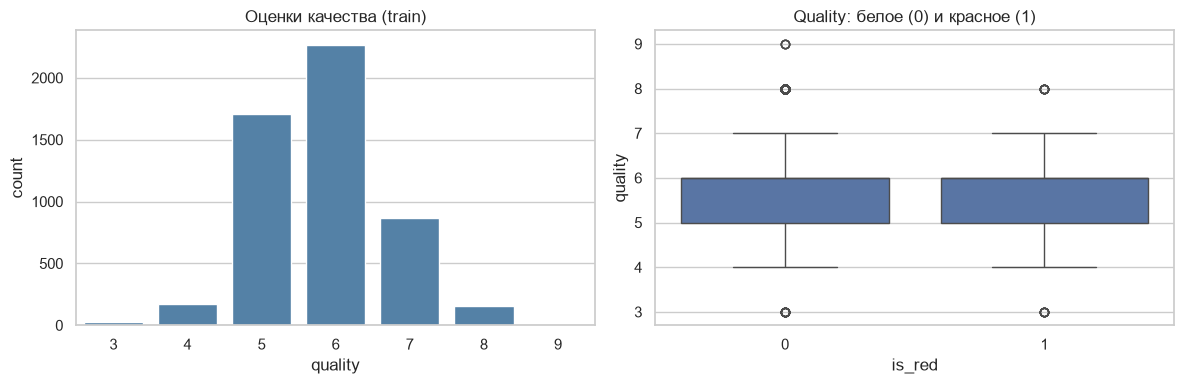

In [4]:
train_view = X_train.assign(quality=y_train)
print("Пропуски (train):")
display(train_view.isna().sum().sort_values(ascending=False).head(12))
print("Распределение quality (train):")
display(y_train.value_counts().sort_index().rename("count").to_frame())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x=y_train, ax=axes[0], color="steelblue")
axes[0].set_title("Оценки качества (train)")
sns.boxplot(data=train_view, x="is_red", y="quality", ax=axes[1])
axes[1].set_title("Quality: белое (0) и красное (1)")
plt.tight_layout()
plt.show()


**Интерпретация:** наиболее частые значения quality можно предсказывать проще; экстремальные оценки представлены небольшим числом примеров, поэтому ошибки на них могут быть выше. Разница распределений по цвету — повод оставить `is_red` среди признаков, но это не доказательство причинного влияния цвета.

,pearson_corr
density,-0.309261
volatile acidity,-0.269667
chlorides,-0.201070
is_red,-0.130964
fixed acidity,-0.087008
total sulfur dioxide,-0.036475
residual sugar,-0.034714
pH,0.017324
sulphates,0.034410
free sulfur dioxide,0.055131


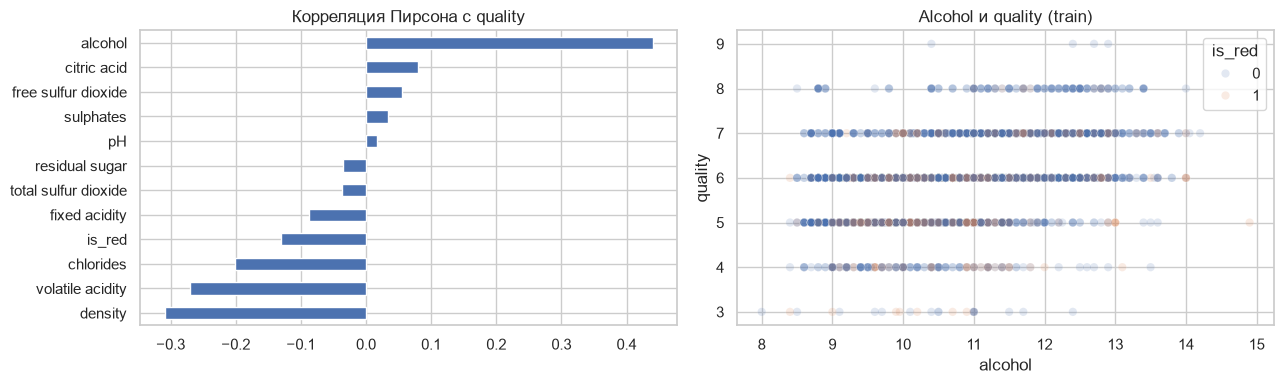

In [5]:
corr = train_view.corr(numeric_only=True)["quality"].drop("quality").sort_values()
display(corr.rename("pearson_corr").to_frame())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
corr.plot.barh(ax=axes[0], title="Корреляция Пирсона с quality")
sns.scatterplot(data=train_view, x="alcohol", y="quality", hue="is_red", alpha=.16, ax=axes[1], legend="brief")
axes[1].set_title("Alcohol и quality (train)")
plt.tight_layout()
plt.show()


**Вывод по EDA:** признаки с наиболее сильной по модулю корреляцией — кандидаты на важные линейные предикторы. Важно проверить, будут ли они столь же значимыми в лесу и бустинге: эти методы учитывают нелинейности и взаимодействия. Корреляции не используются для удаления признаков «на глаз», чтобы избежать необоснованной селекции.

In [6]:
# Небольшой фактический итог EDA (считаем только по train)
quality_counts = y_train.value_counts()
positive = corr.sort_values(ascending=False).head(3)
negative = corr.sort_values().head(3)

print("Чаще всего встречается quality =", quality_counts.idxmax(),
      f"({quality_counts.max()} из {len(y_train)} обучающих объектов).")
print("Три наиболее положительные корреляции с quality:")
display(positive.rename("Pearson r").to_frame().round(3))
print("Три наиболее отрицательные корреляции с quality:")
display(negative.rename("Pearson r").to_frame().round(3))
print("Интерпретация: это линейные статистические связи, а не доказательства причинного влияния.")


Чаще всего встречается quality = 6 (2269 из 5197 обучающих объектов).
Три наиболее положительные корреляции с quality:


,Pearson r
alcohol,0.440
citric acid,0.080
free sulfur dioxide,0.055


Три наиболее отрицательные корреляции с quality:


,Pearson r
density,-0.309
volatile acidity,-0.270
chlorides,-0.201


Интерпретация: это линейные статистические связи, а не доказательства причинного влияния.


## 4. Метрики и константный baseline

**MAE** — средняя абсолютная ошибка (в баллах качества); **RMSE** — корень из средней квадратичной ошибки. Возведение в квадрат делает RMSE более чувствительной к большим промахам. Поэтому MAE и RMSE для той же модели могут различаться, если есть редкие очень большие ошибки.

Для минимизации **MSE и RMSE** оптимальная константа — **среднее арифметическое y на обучении**, не медиана. На CV среднее вычисляется на каждом тренировочном фолде через `DummyRegressor(strategy="mean")`.

In [7]:
def metrics(y_true, y_pred):
    return {"RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE": mean_absolute_error(y_true, y_pred)}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"}
baseline = DummyRegressor(strategy="mean")
cv_base = cross_validate(baseline, X_train, y_train, cv=cv, scoring=scoring)
print("Baseline: CV RMSE =", round(-cv_base["test_rmse"].mean(), 4),
      "| CV MAE =", round(-cv_base["test_mae"].mean(), 4))


Baseline: CV RMSE = 0.8732 | CV MAE = 0.6856


## 5. Обязательные модели: Linear Regression, Random Forest и Gradient Boosting

Линейная модель использует `StandardScaler` для корректного сравнения коэффициентов в стандартных отклонениях; импутация обучается внутри Pipeline. Лес и бустинг не требуют масштабирования. Для выбора параметров используется **только** 5-fold CV на train; все сравниваются по одной и той же основной метрике **RMSE** и с одинаковыми фолдами.

In [8]:
linear = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression()),
])
forest = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)),
])
boosting = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", GradientBoostingRegressor(random_state=RANDOM_STATE)),
])

experiments = {
    "Linear Regression": (linear, {}),
    "Random Forest": (forest, {
        "model__n_estimators": [200, 400],
        "model__max_depth": [None, 12],
        "model__min_samples_leaf": [1, 3],
    }),
    "Gradient Boosting": (boosting, {
        "model__n_estimators": [150, 300],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [2, 3],
    })
}


In [9]:
from sklearn.base import clone

cv_rows = [{
    "Модель": "Baseline",
    "CV RMSE": -cv_base["test_rmse"].mean(),
    "CV MAE": -cv_base["test_mae"].mean()
}]
fitted_models = {"Baseline": clone(baseline).fit(X_train, y_train)}
best_params = {}

for name, (estimator, grid) in experiments.items():
    if grid:
        search = GridSearchCV(estimator, grid, scoring="neg_root_mean_squared_error",
                              cv=cv, n_jobs=-1, refit=True)
        search.fit(X_train, y_train)
        selected = search.best_estimator_
        best_params[name] = search.best_params_
    else:
        selected = clone(estimator).fit(X_train, y_train)
        best_params[name] = "без настраиваемых гиперпараметров"
    # Честная CV-оценка выбранного значения гиперпараметров;
    # для подбора сетки это слегка оптимистичная оценка, так как выбирали по тем же фолдам.
    scores = cross_validate(selected, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_rows.append({"Модель": name, "CV RMSE": -scores["test_rmse"].mean(),
                    "CV MAE": -scores["test_mae"].mean()})
    fitted_models[name] = selected
    print(name, "| параметры:", best_params[name])

cv_table = pd.DataFrame(cv_rows).sort_values("CV RMSE").reset_index(drop=True)
display(cv_table.round(4))
best_name = cv_table.iloc[0]["Модель"]
print("Выбрана по CV:", best_name)


Linear Regression | параметры: без настраиваемых гиперпараметров


Random Forest | параметры: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 400}


Gradient Boosting | параметры: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 300}


,Модель,CV RMSE,CV MAE
0,Random Forest,0.6230,0.4508
1,Gradient Boosting,0.6762,0.5225
2,Linear Regression,0.7377,0.5710
3,Baseline,0.8732,0.6856


Выбрана по CV: Random Forest


**Важно:** при подборе гиперпараметров максимизация по той же CV-сетке может делать CV-результат слегка оптимистичным. Для учебного сравнения этого достаточно; в строгом исследовании применяют nested cross-validation. Финальный test ниже не участвует в выборе.

## 5.1. Дополнительная модель линейного семейства: RBF + Ridge

Обычная `LinearRegression` остаётся отдельной моделью. Здесь используем **Ridge-регрессию в пространстве нелинейных RBF-признаков**: `Nystroem` приближает RBF-ядро $k(x, z) = \exp(-\gamma \|x-z\|^2)$, а Ridge обучает линейные веса новых признаков с L2-регуляризацией. По исходным химическим признакам зависимость нелинейна; это не обычная Linear Regression.

Весь путь `SimpleImputer → StandardScaler → Nystroem → Ridge` находится внутри `Pipeline`: медианы, масштабирование и опорные объекты для RBF-признаков определяются только на тренировочной части каждого CV-фолда. Масштабирование нужно, поскольку RBF использует расстояния между объектами.

Проверяем `gamma ∈ [0.02, 0.04, 0.08, 0.12]`, `alpha ∈ [0.0001, 0.001, 0.01, 0.1, 1]` и `n_components=200` на том же объекте пятикратной CV. `GridSearchCV` считает RMSE и MAE, но выбирает параметры **только по CV RMSE**. Все 20 комбинаций сохраняются в `rbf_cv_results`; тест до финальной оценки не используется.


In [10]:
rbf_ridge = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("rbf", Nystroem(kernel="rbf", n_components=200, random_state=RANDOM_STATE)),
    ("model", Ridge()),
])
rbf_grid = {
    "rbf__gamma": [0.02, 0.04, 0.08, 0.12],
    "model__alpha": [0.0001, 0.001, 0.01, 0.1, 1],
}
rbf_search = GridSearchCV(
    rbf_ridge, rbf_grid, scoring=scoring, refit="rmse",
    cv=cv, n_jobs=-1, error_score="raise",
)
rbf_search.fit(X_train, y_train)

# Сохраняем результаты всех комбинаций и обе метрики одной и той же CV.
rbf_cv_results = pd.DataFrame(rbf_search.cv_results_)
rbf_cv_results["n_components"] = 200
rbf_cv_results["CV RMSE"] = -rbf_cv_results["mean_test_rmse"]
rbf_cv_results["CV MAE"] = -rbf_cv_results["mean_test_mae"]
display(rbf_cv_results[[
    "n_components", "param_rbf__gamma", "param_model__alpha", "CV RMSE", "CV MAE"
]].sort_values("CV RMSE").round(4))

# best_estimator_ уже переобучен GridSearchCV на всём train, без test.
fitted_models["RBF + Ridge"] = rbf_search.best_estimator_
best_params["RBF + Ridge"] = {
    **rbf_search.best_params_,
    "rbf__n_components": rbf_search.best_estimator_.named_steps["rbf"].n_components,
}
rbf_best = rbf_cv_results.loc[rbf_search.best_index_]
cv_rows.append({
    "Модель": "RBF + Ridge",
    "CV RMSE": rbf_best["CV RMSE"],
    "CV MAE": rbf_best["CV MAE"],
})
cv_table = pd.DataFrame(cv_rows).sort_values("CV RMSE").reset_index(drop=True)
linear_comparison = cv_table.set_index("Модель").loc[
    ["Linear Regression", "RBF + Ridge"], ["CV RMSE", "CV MAE"]
]
print("Сравнение с исходной Linear Regression на одинаковых CV-фолдах:")
display(linear_comparison.round(4))
print("Уменьшение CV-ошибок (Linear Regression − RBF + Ridge):")
display((linear_comparison.loc["Linear Regression"] - linear_comparison.loc["RBF + Ridge"]).round(4))
print("Выбранные параметры RBF + Ridge:", best_params["RBF + Ridge"])
print("RBF + Ridge: CV RMSE < 0.70:", rbf_best["CV RMSE"] < 0.70)
display(cv_table.round(4))
best_name = cv_table.iloc[0]["Модель"]
print("Выбрана по CV среди всех моделей:", best_name)


,n_components,param_rbf__gamma,param_model__alpha,CV RMSE,CV MAE
18,200,0.08,1.0000,0.6903,0.5363
14,200,0.08,0.1000,0.6909,0.5369
13,200,0.04,0.1000,0.6909,0.5378
17,200,0.04,1.0000,0.6916,0.5379
10,200,0.08,0.0100,0.6921,0.5377
12,200,0.02,0.1000,0.6921,0.5388
6,200,0.08,0.0010,0.6923,0.5378
2,200,0.08,0.0001,0.6923,0.5379
19,200,0.12,1.0000,0.6932,0.5381
9,200,0.04,0.0100,0.6938,0.5400


Сравнение с исходной Linear Regression на одинаковых CV-фолдах:


,CV RMSE,CV MAE
Модель,,
Linear Regression,0.7377,0.5710
RBF + Ridge,0.6903,0.5363


Уменьшение CV-ошибок (Linear Regression − RBF + Ridge):


CV RMSE    0.0474
CV MAE     0.0347
dtype: float64

Выбранные параметры RBF + Ridge: {'model__alpha': 1, 'rbf__gamma': 0.08, 'rbf__n_components': 200}
RBF + Ridge: CV RMSE < 0.70: True


,Модель,CV RMSE,CV MAE
0,Random Forest,0.6230,0.4508
1,Gradient Boosting,0.6762,0.5225
2,RBF + Ridge,0.6903,0.5363
3,Linear Regression,0.7377,0.5710
4,Baseline,0.8732,0.6856


Выбрана по CV среди всех моделей: Random Forest


**Результат подбора на train:** при `gamma=0.08`, `alpha=1`, `n_components=200` получаем CV RMSE ≈ **0.6903** и CV MAE ≈ **0.5363**. У исходной Linear Regression — **0.7377** и **0.5710** соответственно: уменьшение составляет примерно **0.0474 RMSE** и **0.0347 MAE**. На CV порог 0.70 достигнут уже с 200 компонентами, поэтому поиск с 300–400 компонентами не требуется. Эти параметры фиксируются до обращения к тестовой выборке.

Как и у ансамблей, оценка лучшего варианта по той же CV может быть оптимистичной из-за перебора параметров; это не nested CV. Коэффициенты Ridge относятся к RBF-признакам, поэтому их нельзя интерпретировать как коэффициенты исходных химических признаков. Обязательный анализ исходной Linear Regression и importance ансамблей сохранён ниже.


## 6. Коэффициенты линейной модели и importance деревьев

После `StandardScaler` абсолютные коэффициенты линейной модели сопоставимы по масштабу: они описывают изменение предсказания при росте признака на одно стандартное отклонение **при прочих равных**. Однако коррелированные признаки и масштабирование бинарного `is_red` осложняют содержательную интерпретацию. В деревьях impurity-based importance может смещаться в пользу непрерывных признаков; feature importance не устанавливает причинность.

,Linear |standardized coef|,Forest importance,Boosting importance
alcohol,0.256,0.248,0.365
volatile acidity,0.242,0.132,0.170
free sulfur dioxide,0.086,0.088,0.092
sulphates,0.109,0.077,0.062
residual sugar,0.309,0.076,0.066
total sulfur dioxide,0.091,0.072,0.059
pH,0.088,0.070,0.043
chlorides,0.022,0.063,0.037
fixed acidity,0.112,0.058,0.036
citric acid,0.014,0.057,0.031


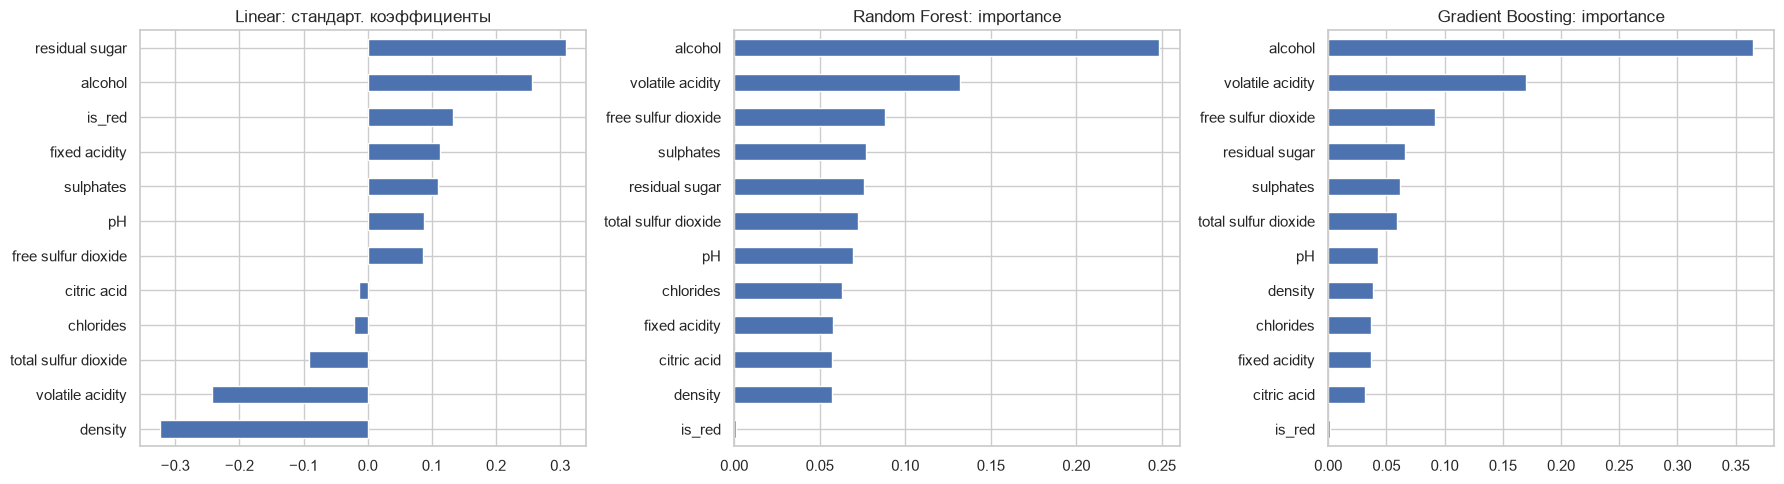

Топ-5 Forest: ['alcohol', 'volatile acidity', 'free sulfur dioxide', 'sulphates', 'residual sugar']
Топ-5 Boosting: ['alcohol', 'volatile acidity', 'free sulfur dioxide', 'residual sugar', 'sulphates']
Пересечение топ-5: ['alcohol', 'free sulfur dioxide', 'residual sugar', 'sulphates', 'volatile acidity']


In [11]:
features = X_train.columns.tolist()
coef = pd.Series(fitted_models["Linear Regression"].named_steps["model"].coef_, index=features)
importance_rf = pd.Series(fitted_models["Random Forest"].named_steps["model"].feature_importances_, index=features)
importance_gb = pd.Series(fitted_models["Gradient Boosting"].named_steps["model"].feature_importances_, index=features)
display(pd.DataFrame({
    "Linear |standardized coef|": coef.abs().sort_values(ascending=False),
    "Forest importance": importance_rf,
    "Boosting importance": importance_gb
}).fillna(0).sort_values("Forest importance", ascending=False).round(3))
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
coef.sort_values().plot.barh(ax=axs[0], title="Linear: стандарт. коэффициенты")
importance_rf.sort_values().plot.barh(ax=axs[1], title="Random Forest: importance")
importance_gb.sort_values().plot.barh(ax=axs[2], title="Gradient Boosting: importance")
plt.tight_layout()
plt.show()
print("Топ-5 Forest:", importance_rf.nlargest(5).index.tolist())
print("Топ-5 Boosting:", importance_gb.nlargest(5).index.tolist())
print("Пересечение топ-5:", sorted(set(importance_rf.nlargest(5).index) & set(importance_gb.nlargest(5).index)))


**Обсуждение:** сопоставьте топ-признаки графиков с корреляциями из EDA. Различия ожидаемы: линейная регрессия описывает аддитивные линейные эффекты, деревья могут учитывать пороговые зависимости и сочетания. Важность признака **не означает**, что его изменение вызовет изменение качества: возможны корреляции с невидимыми факторами и взаимодействия.

In [12]:
# Конкретное сопоставление по уже обученным моделям
linear_top = coef.abs().nlargest(5).index.tolist()
rf_top = importance_rf.nlargest(5).index.tolist()
gb_top = importance_gb.nlargest(5).index.tolist()
eda_top = corr.abs().nlargest(5).index.tolist()
print("Топ-5 |коэффициентов| линейной регрессии:", linear_top)
print("Топ-5 Random Forest:", rf_top)
print("Топ-5 Gradient Boosting:", gb_top)
print("Топ-5 |корреляций Пирсона| из EDA:", eda_top)
print("Общие признаки у леса и бустинга:", sorted(set(rf_top) & set(gb_top)))
print("Общие признаки у леса и EDA:", sorted(set(rf_top) & set(eda_top)))
print("Вывод: разницу ранжирования можно объяснять нелинейными эффектами, взаимодействиями")
print("и корреляциями между признаками; feature importance не доказывает причинно-следственную связь.")


Топ-5 |коэффициентов| линейной регрессии: ['density', 'residual sugar', 'alcohol', 'volatile acidity', 'is_red']
Топ-5 Random Forest: ['alcohol', 'volatile acidity', 'free sulfur dioxide', 'sulphates', 'residual sugar']
Топ-5 Gradient Boosting: ['alcohol', 'volatile acidity', 'free sulfur dioxide', 'residual sugar', 'sulphates']
Топ-5 |корреляций Пирсона| из EDA: ['alcohol', 'density', 'volatile acidity', 'chlorides', 'is_red']
Общие признаки у леса и бустинга: ['alcohol', 'free sulfur dioxide', 'residual sugar', 'sulphates', 'volatile acidity']
Общие признаки у леса и EDA: ['alcohol', 'volatile acidity']
Вывод: разницу ранжирования можно объяснять нелинейными эффектами, взаимодействиями
и корреляциями между признаками; feature importance не доказывает причинно-следственную связь.


## 7. Финальная тестовая оценка — один раз, после выбора по CV

Все модели оцениваются на **том же** `X_test`; ни одна не дообучается на нём и параметры не меняются на основе таблицы. Таблица обязательно включает baseline, RMSE и MAE. **Победителя выбирали по CV**, а не по тестовой метрике.

In [13]:
test_rows = []
predictions = {}
model_order = ["Baseline", "Linear Regression", "RBF + Ridge", "Random Forest", "Gradient Boosting"]
for name in model_order:
    pred = fitted_models[name].predict(X_test)
    predictions[name] = pred
    test_rows.append({"Модель": name, **metrics(y_test, pred)})
test_table = pd.DataFrame(test_rows).set_index("Модель").loc[
    model_order
]
# В итоговой таблице сохраняем test RMSE/MAE и добавляем train CV для сравнения.
test_table = test_table.join(cv_table.set_index("Модель")[["CV RMSE", "CV MAE"]])
display(test_table.round(4))
print("RBF + Ridge | выбранные по train CV параметры:", best_params["RBF + Ridge"])
print("RBF + Ridge | локальный test RMSE < 0.70:", test_table.loc["RBF + Ridge", "RMSE"] < 0.70)
print("Порог скрытого теста RMSE < 0.70: локальная проверка НЕ подтверждает прохождение leaderboard.")
print("Выбранная по CV модель:", best_name)
print("Её локальный test RMSE:", round(test_table.loc[best_name, "RMSE"], 4))
print("Превзошли константу (test):", test_table.index[test_table["RMSE"] < test_table.loc["Baseline", "RMSE"]].tolist())


,RMSE,MAE,CV RMSE,CV MAE
Модель,,,,
Baseline,0.8738,0.6861,0.8732,0.6856
Linear Regression,0.7280,0.5678,0.7377,0.5710
RBF + Ridge,0.6904,0.5348,0.6903,0.5363
Random Forest,0.6051,0.4300,0.6230,0.4508
Gradient Boosting,0.6640,0.5165,0.6762,0.5225


RBF + Ridge | выбранные по train CV параметры: {'model__alpha': 1, 'rbf__gamma': 0.08, 'rbf__n_components': 200}
RBF + Ridge | локальный test RMSE < 0.70: True
Порог скрытого теста RMSE < 0.70: локальная проверка НЕ подтверждает прохождение leaderboard.
Выбранная по CV модель: Random Forest
Её локальный test RMSE: 0.6051
Превзошли константу (test): ['Linear Regression', 'RBF + Ridge', 'Random Forest', 'Gradient Boosting']


In [14]:
# Фактическое сравнение итоговых результатов (после единственной тестовой оценки)
baseline_rmse = test_table.loc["Baseline", "RMSE"]
result = test_table.loc[best_name]
print("Лучшая по CV модель:", best_name)
print(f"Её test RMSE = {result['RMSE']:.4f}, test MAE = {result['MAE']:.4f}.")
print(f"Относительное снижение RMSE по сравнению с константным baseline: "
      f"{100 * (baseline_rmse - result['RMSE']) / baseline_rmse:.1f}%.")
print("Локальный тест соответствует целевому порогу < 0.70:",
      "ДА" if result["RMSE"] < 0.70 else "НЕТ")
print("Важно: скрытая тестовая выборка leaderboard не проверена этим запуском.")


Лучшая по CV модель: Random Forest
Её test RMSE = 0.6051, test MAE = 0.4300.
Относительное снижение RMSE по сравнению с константным baseline: 30.7%.
Локальный тест соответствует целевому порогу < 0.70: ДА
Важно: скрытая тестовая выборка leaderboard не проверена этим запуском.


## 8. Анализ ошибок выбранной по CV модели

Рассмотрим остатки `y_true - y_pred`, наиболее крупные ошибки, средние ошибки по значениям `quality` и различия между редкими/частыми оценками. Редкие классы часто сложнее: модель обучается в основном на типичных оценках, а RMSE не гарантирует равного качества на всех подгруппах.

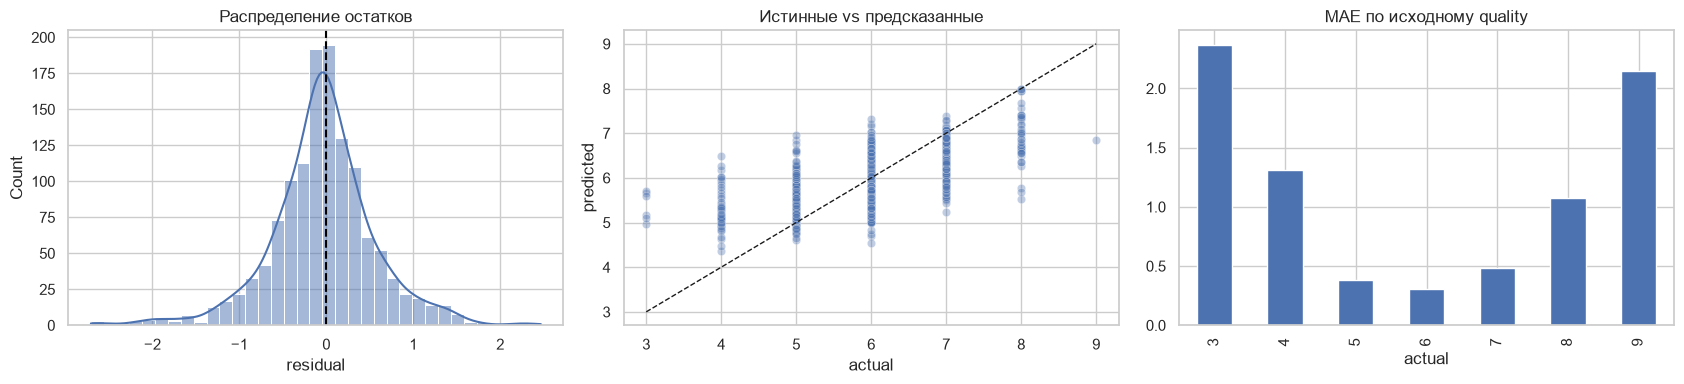

Топ-10 крупных ошибок:


,actual,predicted,residual,absolute_error
2339,3,5.708,-2.707,2.707
3287,3,5.670,-2.670,2.670
1850,3,5.600,-2.600,2.600
6107,4,6.498,-2.497,2.497
3005,8,5.532,2.468,2.468
1403,8,5.685,2.315,2.315
3718,4,6.255,-2.255,2.255
440,8,5.762,2.238,2.238
1469,3,5.178,-2.178,2.178
3715,4,6.168,-2.168,2.168


Ошибки по оценкам quality:


,n,MAE,mean_prediction
actual,,,
3,6,2.371,5.371
4,43,1.311,5.311
5,428,0.385,5.371
6,567,0.310,5.944
7,216,0.481,6.538
8,39,1.072,6.928
9,1,2.148,6.852


In [15]:
best_pred = predictions[best_name]
errors = pd.DataFrame({"actual": y_test, "predicted": best_pred}, index=y_test.index)
errors["residual"] = errors["actual"] - errors["predicted"]
errors["absolute_error"] = errors["residual"].abs()

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(data=errors, x="residual", bins=35, kde=True, ax=axes[0])
axes[0].axvline(0, color="black", linestyle="--")
axes[0].set_title("Распределение остатков")
sns.scatterplot(data=errors, x="actual", y="predicted", alpha=.35, ax=axes[1])
axes[1].plot([y.min(), y.max()], [y.min(), y.max()], "k--", linewidth=1)
axes[1].set_title("Истинные vs предсказанные")
errors.groupby("actual")["absolute_error"].mean().plot.bar(ax=axes[2], title="MAE по исходному quality")
plt.tight_layout()
plt.show()

print("Топ-10 крупных ошибок:")
display(errors.nlargest(10, "absolute_error").round(3))
print("Ошибки по оценкам quality:")
display(errors.groupby("actual").agg(
    n=("absolute_error", "size"),
    MAE=("absolute_error", "mean"),
    mean_prediction=("predicted", "mean")
).round(3))


In [16]:
print("Объекты с крупнейшими ошибками (только анализ, без перенастройки):")
worst = errors.nlargest(5, "absolute_error")
display(X_test.loc[worst.index].join(worst).round(3))
print("Количество train-примеров каждой оценки:")
display(y_train.value_counts().sort_index().rename("train_count").to_frame())


Объекты с крупнейшими ошибками (только анализ, без перенастройки):


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,is_red,actual,predicted,residual,absolute_error
2339,6.9,0.39,0.40,4.60,0.022,5.0,19.0,0.992,3.31,0.37,12.6,0,3,5.708,-2.707,2.707
3287,6.7,0.25,0.26,1.55,0.041,118.5,216.0,0.995,3.55,0.63,9.4,0,3,5.670,-2.670,2.670
1850,8.5,0.26,0.21,16.20,0.074,41.0,197.0,0.998,3.02,0.50,9.8,0,3,5.600,-2.600,2.600
6107,5.8,0.26,0.30,2.60,0.034,75.0,129.0,0.990,3.20,0.38,11.5,0,4,6.498,-2.497,2.497
3005,8.2,0.22,0.36,6.80,0.034,12.0,90.0,0.994,3.01,0.38,10.5,0,8,5.532,2.468,2.468


Количество train-примеров каждой оценки:


,train_count
quality,
3,24
4,173
5,1710
6,2269
7,863
8,154
9,4


In [17]:
# Аналитический вывод по ошибкам: цифры формируются из тестовой таблицы
quality_error = errors.groupby("actual").agg(
    count=("absolute_error", "size"),
    mae=("absolute_error", "mean"),
    mean_prediction=("predicted", "mean"),
).sort_index()
worst_label = quality_error["mae"].idxmax()
print(f"Наибольшая средняя абсолютная ошибка по группам — для quality={worst_label}: "
      f"{quality_error.loc[worst_label, 'mae']:.3f} "
      f"(объектов: {int(quality_error.loc[worst_label, 'count'])}).")
print("Три самых крупных индивидуальных промаха:")
display(errors.nlargest(3, "absolute_error").round(3))
print("Возможное объяснение: оценки на краях шкалы и редко представленные группы")
print("могут хуже предсказываться; регрессор часто тяготеет к центральным значениям quality.")
print("Это гипотеза по наблюдаемым ошибкам, а не установленная причинная связь.")


Наибольшая средняя абсолютная ошибка по группам — для quality=3: 2.371 (объектов: 6).
Три самых крупных индивидуальных промаха:


,actual,predicted,residual,absolute_error
2339,3,5.708,-2.707,2.707
3287,3,5.670,-2.670,2.670
1850,3,5.600,-2.600,2.600


Возможное объяснение: оценки на краях шкалы и редко представленные группы
могут хуже предсказываться; регрессор часто тяготеет к центральным значениям quality.
Это гипотеза по наблюдаемым ошибкам, а не установленная причинная связь.


## 9. Итоговые выводы и ограничения

**Дополнительный эксперимент RBF + Ridge:** выбранные только по train CV параметры — `gamma=0.08`, `alpha=1`, `n_components=200`. CV RMSE / MAE = **0.6903 / 0.5363**, финальные test RMSE / MAE = **0.6904 / 0.5348**. Порог RMSE < 0.70 достигнут на обеих выборках; после оценки на test параметры не менялись. Исходная Linear Regression сохранена: CV RMSE / MAE = **0.7377 / 0.5710**, test RMSE / MAE = **0.7280 / 0.5678**. Лучшей среди всех моделей по CV остаётся Random Forest.

Выводы ниже строятся автоматически из **фактически рассчитанных** метрик и важностей. Для защиты ориентируемся на таблицы и графики выше.

- Основное сравнение проводится на одинаковых CV-фолдах: константный baseline, Linear Regression, RBF + Ridge, Random Forest и Gradient Boosting.
- **Выбор модели делается по CV**, а не по test; отдельная финальная тестовая оценка выполняется только после выбора.
- Для RMSE оптимальный константный baseline использует **среднее** `quality` по train. MAE измеряет среднюю абсолютную ошибку; RMSE сильнее штрафует большие отклонения.
- Стандартизированные коэффициенты линейной регрессии позволяют сравнивать масштабы эффектов при прочих равных, но коррелированные признаки осложняют интерпретацию.
- Важность признаков у ансамблей отражает их полезность для модели, **не причинное влияние** на качество вина.
- Редкие оценки `quality` и повторяющиеся наборы характеристик ограничивают надёжность оценки; локальный test может отличаться от скрытого теста преподавателя.

**Ограничения эксперимента:** среди исходных вин есть повторяющиеся записи, из-за чего случайное train/test-разделение и KFold могут несколько завышать качество при наличии одинаковых признаков в обеих частях. Гиперпараметры выбраны на той же CV-сетке, на которой приведены CV-оценки, поэтому эти оценки могут быть оптимистичны. Дополнительно можно изучить GroupKFold или nested CV, но не использовать скрытый test для подбора параметров.

**Для защиты:** уметь объяснить train/test, CV, Pipeline, выбор среднего baseline, различия MAE/RMSE, коэффициенты линейной модели, feature importance и причины ошибок на редких значениях.

In [18]:
print("Окончательное сравнение на test (чем ниже — тем лучше):")
display(test_table.round(4))
print(f"Модель выбрана по CV: {best_name}; локальный test RMSE = {test_table.loc[best_name, 'RMSE']:.4f}.")
print("Гиперпараметры выбранной модели:", best_params.get(best_name))
print("Итог: все обязательные модели и baseline оценены по единому протоколу.")
print("Для leaderboard требуется отдельная оценка на скрытой выборке преподавателя.")


Окончательное сравнение на test (чем ниже — тем лучше):


,RMSE,MAE,CV RMSE,CV MAE
Модель,,,,
Baseline,0.8738,0.6861,0.8732,0.6856
Linear Regression,0.7280,0.5678,0.7377,0.5710
RBF + Ridge,0.6904,0.5348,0.6903,0.5363
Random Forest,0.6051,0.4300,0.6230,0.4508
Gradient Boosting,0.6640,0.5165,0.6762,0.5225


Модель выбрана по CV: Random Forest; локальный test RMSE = 0.6051.
Гиперпараметры выбранной модели: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 400}
Итог: все обязательные модели и baseline оценены по единому протоколу.
Для leaderboard требуется отдельная оценка на скрытой выборке преподавателя.
